<a href="https://colab.research.google.com/github/ThippanaSathvik-IIT/ml-ps0/blob/main/cifar100_hyperparameter_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 # CIFAR-100 Image Classification: Hyperparameter Tuning Challenge

Welcome! In this notebook you will train a small convolutional neural network (CNN) to recognise **100 kinds of objects** in tiny 32x32 colour images.

**Your mission is not just to run the code. It is to improve it.**

The model code is given to you. Your job is to change the **hyperparameters** (learning rate, batch size, dropout, and so on), run experiment after experiment, and keep a record of what worked and what did not, until you reach the best validation accuracy you can.

### How this notebook works
1. Run Steps 0 to 4 once, top to bottom (this gives you a baseline).
2. In Step 5, change **one hyperparameter at a time** and run again.
3. Every run is **logged automatically** into a results table (Step 6).
4. When you are happy with your best model, evaluate it **once** on the test set (Step 7).

> Tip: use **Runtime > Run all** the first time, then work cell by cell.

## Step 0: Set up (GPU)

Training on a CPU is very slow. Please switch to a free GPU:

**Runtime > Change runtime type > T4 GPU > Save**

Then run the cell below. You should see at least one GPU listed.

In [ ]:
import random, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A fixed seed makes your results (mostly) repeatable, so comparisons between runs are fair.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load a SMALL version of CIFAR-100

The full CIFAR-100 (60,000 images, about 160 MB) can be slow or fail to download on Colab. So this notebook loads a **small slice** instead:

- It **streams** only the images it needs from the Hugging Face copy of CIFAR-100 (same data as on Kaggle), so the download is a fraction of the full size.
- It keeps only **NUM_CLASSES** of the 100 classes (20 by default), which also makes training much faster.
- If streaming fails, it automatically falls back to the normal Keras download and then slices it.

You can change the three size settings below. Bigger means more accurate but slower.

We split the data into three parts:

| Part | Used for |
|------|----------|
| Train | Teaching the model |
| Validation | **Comparing your experiments** (look at it as often as you like) |
| Test | The final exam. Use it **once**, at the very end. |

If you tune using the test set, your final score will be unfairly optimistic. That is called *data leakage*, so please resist the temptation.

In [ ]:
# ---------- Size settings for the short version (you may change these) ----------
NUM_CLASSES = 20      # how many of the 100 classes to keep (100 = all classes)
TRAIN_POOL = 20000    # images read from the original training set (max 50000)
TEST_POOL = 4000      # images read from the original test set (max 10000)
VAL_FRACTION = 0.15   # share of the kept training images used for validation
# Rough guide: images kept = TRAIN_POOL * NUM_CLASSES / 100 (so 20000 and 20 classes gives about 4000)

ALL_CLASS_NAMES = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle',
 'bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle',
 'chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur',
 'dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','keyboard',
 'lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain',
 'mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree',
 'plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket',
 'rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider',
 'squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor',
 'train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm']
assert len(ALL_CLASS_NAMES) == 100


def load_stream(split, n):
    # Reads only n images from the Hugging Face copy of CIFAR-100 (small download)
    from datasets import load_dataset
    ds = load_dataset("uoft-cs/cifar100", split=split, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10000)
    xs, ys = [], []
    for ex in ds.take(n):
        xs.append(np.array(ex["img"].convert("RGB"), dtype=np.uint8))
        ys.append(ex["fine_label"])
    return np.stack(xs), np.array(ys)


try:
    x_tr, y_tr = load_stream("train", TRAIN_POOL)
    x_te, y_te = load_stream("test", TEST_POOL)
    print("Loaded a small slice via Hugging Face streaming.")
except Exception as e:
    print("Streaming did not work (", repr(e)[:120], ").")
    print("Falling back to the Keras download (about 160 MB, one time only).")
    (xa, ya), (xb, yb) = keras.datasets.cifar100.load_data(label_mode="fine")
    r = np.random.RandomState(SEED)
    ia, ib = r.permutation(len(xa))[:TRAIN_POOL], r.permutation(len(xb))[:TEST_POOL]
    x_tr, y_tr, x_te, y_te = xa[ia], ya.flatten()[ia], xb[ib], yb.flatten()[ib]

# Keep only some classes, and renumber them 0 .. NUM_CLASSES-1
chosen = np.sort(np.random.RandomState(SEED).choice(100, NUM_CLASSES, replace=False))
remap = {int(c): i for i, c in enumerate(chosen)}
CLASS_NAMES = [ALL_CLASS_NAMES[c] for c in chosen]

def keep_classes(x, y):
    m = np.isin(y, chosen)
    return x[m], np.array([remap[int(c)] for c in y[m]])

x_tr, y_tr = keep_classes(x_tr, y_tr)
x_test, y_test = keep_classes(x_te, y_te)

# Train / validation split
perm = np.random.RandomState(SEED).permutation(len(x_tr))
n_val = int(len(x_tr) * VAL_FRACTION)
x_val, y_val = x_tr[perm[:n_val]], y_tr[perm[:n_val]]
x_train, y_train = x_tr[perm[n_val:]], y_tr[perm[n_val:]]

print(f"Classes: {NUM_CLASSES} | Train: {len(x_train)} | Validation: {len(x_val)} | Test: {len(x_test)}")
print("Classes kept:", CLASS_NAMES)
print("Random guessing would score about", f"{100 / NUM_CLASSES:.1f}%")

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

Loaded a small slice via Hugging Face streaming.
Classes: 20 | Train: 3391 | Validation: 598 | Test: 812
Classes kept: ['apple', 'beaver', 'bowl', 'bridge', 'caterpillar', 'clock', 'dolphin', 'elephant', 'forest', 'keyboard', 'lizard', 'lobster', 'orange', 'rose', 'shark', 'skyscraper', 'snail', 'squirrel', 'sweet_pepper', 'train']
Random guessing would score about 5.0%


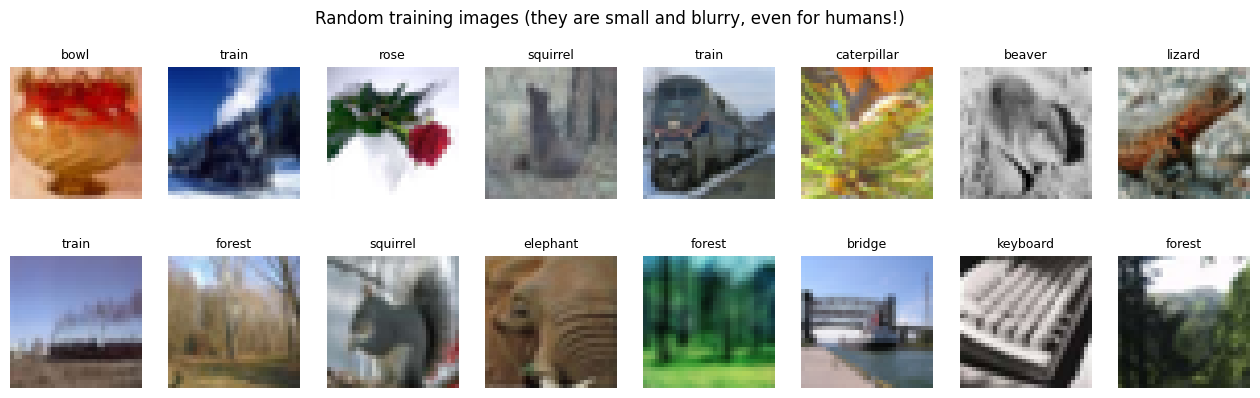

In [ ]:
# Take a look at some images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(x_train), 16, replace=False)):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Random training images (they are small and blurry, even for humans!)")
plt.show()

## Step 2: The model (you do not need to edit this)

This function builds a CNN from a dictionary of settings called `cfg`. Each block has two convolution layers, batch normalisation, max pooling and dropout. The number of filters doubles after every block.

Read it, get curious about it, but all the tuning in this challenge happens through the `cfg` dictionary.

In [ ]:
def build_model(cfg):
    reg = keras.regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)          # turn pixel values 0-255 into 0-1

    # Data augmentation: random changes to training images (only active while training)
    if cfg["augment"]:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomRotation(0.05)(x)

    filters = cfg["base_filters"]
    for _ in range(cfg["num_blocks"]):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(cfg["dropout"])(x)
        filters *= 2

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)


def get_optimizer(cfg):
    name, lr = cfg["optimizer"].lower(), cfg["learning_rate"]
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "adamw":
        return keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError("optimizer must be one of: adam, adamw, sgd, rmsprop")

## Step 3: The experiment runner (you do not need to edit this)

`run_experiment(cfg, notes)` does everything for one experiment:
- builds and trains the model with your settings,
- stops early if the model stops improving (saves time),
- plots the learning curves,
- **adds a row to your results table** and saves it to `experiment_log.csv`,
- keeps a copy of the best model so far in `best_model.keras`.

The `notes` text is for you: write what you changed and why.

In [ ]:
LOG_FILE, BEST_MODEL_FILE = "experiment_log.csv", "best_model.keras"

# Reload earlier results if the file exists (handy if you rerun this cell)
if os.path.exists(LOG_FILE):
    experiment_log = pd.read_csv(LOG_FILE).to_dict("records")
else:
    experiment_log = []
best_val_so_far = max([r["val_acc"] for r in experiment_log], default=0.0) if os.path.exists(BEST_MODEL_FILE) else 0.0


def make_ds(x, y, batch_size, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(history.history["loss"], label="train"); a1.plot(history.history["val_loss"], label="validation")
    a1.set_title("Loss (lower is better)"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(history.history["accuracy"], label="train"); a2.plot(history.history["val_accuracy"], label="validation")
    a2.set_title("Accuracy (higher is better)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.show()


def run_experiment(cfg, notes=""):
    global best_val_so_far
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    train_ds = make_ds(x_train, y_train, cfg["batch_size"], training=True)
    val_ds = make_ds(x_val, y_val, cfg["batch_size"], training=False)

    model = build_model(cfg)
    model.compile(optimizer=get_optimizer(cfg), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=cfg["patience"],
                                               restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs"], callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60

    h = history.history
    best = int(np.argmax(h["val_accuracy"]))          # the epoch with the best validation accuracy
    row = {"run": len(experiment_log) + 1, "notes": notes}
    row.update(cfg)
    row.update({
        "train_acc": round(h["accuracy"][best], 4),
        "val_acc": round(h["val_accuracy"][best], 4),
        "val_loss": round(h["val_loss"][best], 4),
        "gap": round(h["accuracy"][best] - h["val_accuracy"][best], 4),   # big gap = overfitting
        "best_epoch": best + 1,
        "epochs_run": len(h["loss"]),
        "minutes": round(minutes, 1),
        "params": model.count_params(),
    })
    experiment_log.append(row)
    pd.DataFrame(experiment_log).to_csv(LOG_FILE, index=False)

    if row["val_acc"] > best_val_so_far:
        best_val_so_far = row["val_acc"]
        model.save(BEST_MODEL_FILE)
        print("New best model saved!")

    plot_history(history, f"Run {row['run']}: {notes}")
    print(f"Run {row['run']} | val_acc = {row['val_acc']:.4f} | train_acc = {row['train_acc']:.4f} | "
          f"gap = {row['gap']:.4f} | {row['minutes']} min")
    return model

## Step 4: Baseline run

This is the starting point. It uses reasonable but un-tuned settings. Run it and note the validation accuracy. **This is the number you are trying to beat.**

Here is what each setting means:

| Setting | Meaning |
|---------|---------|
| `learning_rate` | How big a step the model takes when learning. Too high: unstable. Too low: very slow. |
| `batch_size` | How many images are used for each update. |
| `epochs` | Maximum passes over the training data (early stopping may end sooner). |
| `optimizer` | The learning algorithm: `adam`, `adamw`, `sgd`, `rmsprop`. |
| `dropout` | Fraction of neurons randomly switched off while training (fights overfitting). |
| `l2` | Weight penalty (fights overfitting). `0` means off. |
| `base_filters` | Width of the first conv layer. It doubles each block. Bigger = more capacity. |
| `num_blocks` | Depth of the network (1 to 4). |
| `dense_units` | Size of the fully connected layer before the output. |
| `augment` | `True` randomly flips, shifts and rotates training images. |
| `use_lr_schedule` | `True` halves the learning rate when progress stalls. |
| `patience` | Epochs to wait without improvement before stopping early. |

Epoch 1/30
53/53 - 33s - 615ms/step - accuracy: 0.1955 - loss: 2.5628 - val_accuracy: 0.0803 - val_loss: 2.9881
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2728 - loss: 2.2419 - val_accuracy: 0.0936 - val_loss: 3.3019
Epoch 3/30
53/53 - 0s - 9ms/step - accuracy: 0.3223 - loss: 2.1145 - val_accuracy: 0.1137 - val_loss: 3.8976
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3518 - loss: 1.9890 - val_accuracy: 0.1288 - val_loss: 3.7461
Epoch 5/30
53/53 - 0s - 9ms/step - accuracy: 0.3786 - loss: 1.9111 - val_accuracy: 0.0936 - val_loss: 3.7397
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4199 - loss: 1.7880 - val_accuracy: 0.1505 - val_loss: 4.0993
Epoch 7/30
53/53 - 0s - 9ms/step - accuracy: 0.4370 - loss: 1.7227 - val_accuracy: 0.1455 - val_loss: 3.7802
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4630 - loss: 1.6404 - val_accuracy: 0.1739 - val_loss: 3.3341
Epoch 9/30
53/53 - 0s - 9ms/step - accuracy: 0.4830 - loss: 1.5989 - val_accuracy: 0.2308 - val_loss: 3.0526
Epoch 10/30


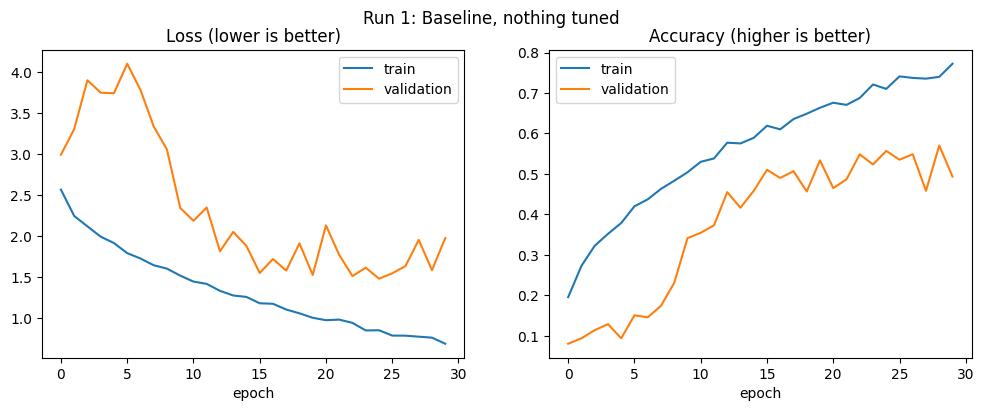

Run 1 | val_acc = 0.5702 | train_acc = 0.7399 | gap = 0.1697 | 0.8 min


In [ ]:
baseline_cfg = {
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 30,
    "optimizer": "adam",
    "dropout": 0.25,
    "l2": 0.0,
    "base_filters": 32,
    "num_blocks": 3,
    "dense_units": 256,
    "augment": False,
    "use_lr_schedule": False,
    "patience": 6,
}

model = run_experiment(baseline_cfg, notes="Baseline, nothing tuned")

## Step 5: YOUR TURN, run experiments

### The golden rule: change ONE thing at a time
If you change three settings and the score goes up, you will not know which change helped.

### The loop
1. Look at the learning curves and the `gap` column from your last run.
2. Form a guess ("The model is overfitting, so more dropout might help").
3. Copy your best config, change **one** value, and write a clear `notes` message.
4. Run it. Check the table in Step 6. Repeat.

### Reading the curves
| What you see | What it probably means | Things to try |
|--------------|------------------------|---------------|
| Train and validation accuracy both low | Underfitting | Bigger model (`base_filters`, `num_blocks`), higher learning rate, train longer |
| Train accuracy high, validation much lower (large `gap`) | Overfitting | `augment=True`, more `dropout`, `l2` > 0, smaller model |
| Validation loss jumps around wildly | Learning rate too high | Lower `learning_rate`, `use_lr_schedule=True` |
| Training is very slow to improve | Learning rate too low | Raise `learning_rate` |
| Stops early at a poor score | `patience` too small | Increase `patience` and `epochs` |

### Ideas for a good search order
1. `augment` (usually a big win on CIFAR-100)
2. `learning_rate` (try 0.01, 0.003, 0.0003)
3. `dropout` (0.1, 0.3, 0.4, 0.5)
4. `use_lr_schedule` and a larger `epochs`
5. Model size: `base_filters` (64) and `num_blocks`
6. `batch_size` (32, 128) and `optimizer`
7. Finally, combine the good ideas and fine-tune around them

Below is a template. Edit the lines marked with `# CHANGE`.

Epoch 1/30
53/53 - 21s - 397ms/step - accuracy: 0.1849 - loss: 2.5772 - val_accuracy: 0.0853 - val_loss: 3.0589
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2524 - loss: 2.2773 - val_accuracy: 0.0502 - val_loss: 3.4945
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3161 - loss: 2.1322 - val_accuracy: 0.0987 - val_loss: 3.7890
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3512 - loss: 1.9979 - val_accuracy: 0.1020 - val_loss: 3.9969
Epoch 5/30
53/53 - 0s - 9ms/step - accuracy: 0.3825 - loss: 1.9141 - val_accuracy: 0.0920 - val_loss: 4.1432
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4037 - loss: 1.8325 - val_accuracy: 0.1589 - val_loss: 3.5557
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4385 - loss: 1.7318 - val_accuracy: 0.1689 - val_loss: 3.3271
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4592 - loss: 1.6657 - val_accuracy: 0.1722 - val_loss: 4.1066
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4751 - loss: 1.6179 - val_accuracy: 0.2475 - val_loss: 2.6956
Epoch 10/

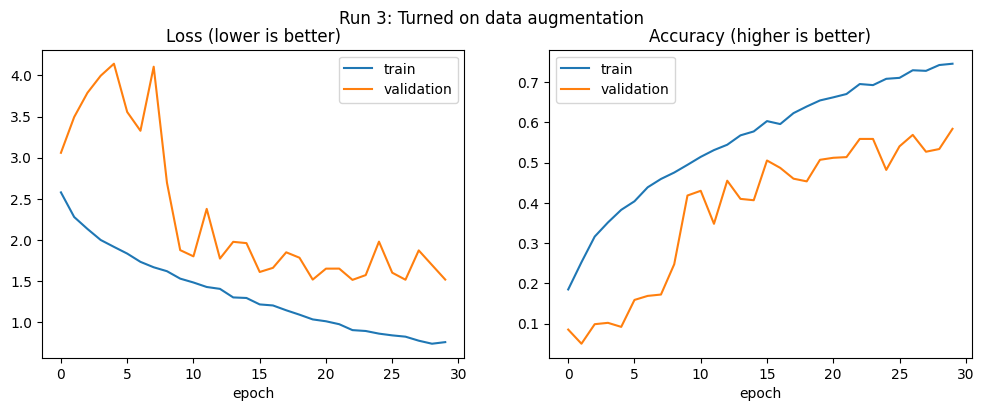

Run 3 | val_acc = 0.5836 | train_acc = 0.7452 | gap = 0.1616 | 0.6 min


In [ ]:
# Experiment 2: copy of the baseline with ONE change
cfg = dict(baseline_cfg)            # start from a known config
cfg["augment"] = False              # CHANGE: the one thing you are testing

model = run_experiment(cfg, notes="changing augment")

Epoch 1/30
53/53 - 18s - 336ms/step - accuracy: 0.1693 - loss: 2.6159 - val_accuracy: 0.0870 - val_loss: 2.9002
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2259 - loss: 2.3414 - val_accuracy: 0.1304 - val_loss: 3.2424
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2695 - loss: 2.2387 - val_accuracy: 0.1538 - val_loss: 3.7820
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2849 - loss: 2.1598 - val_accuracy: 0.1054 - val_loss: 4.4603
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3161 - loss: 2.0825 - val_accuracy: 0.1940 - val_loss: 3.2204
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3430 - loss: 2.0110 - val_accuracy: 0.1756 - val_loss: 3.3310
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3657 - loss: 1.9371 - val_accuracy: 0.2776 - val_loss: 2.6845
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3736 - loss: 1.8743 - val_accuracy: 0.2993 - val_loss: 2.1579
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4014 - loss: 1.8337 - val_accuracy: 0.2843 - val_loss: 2.3766
Epoch 10

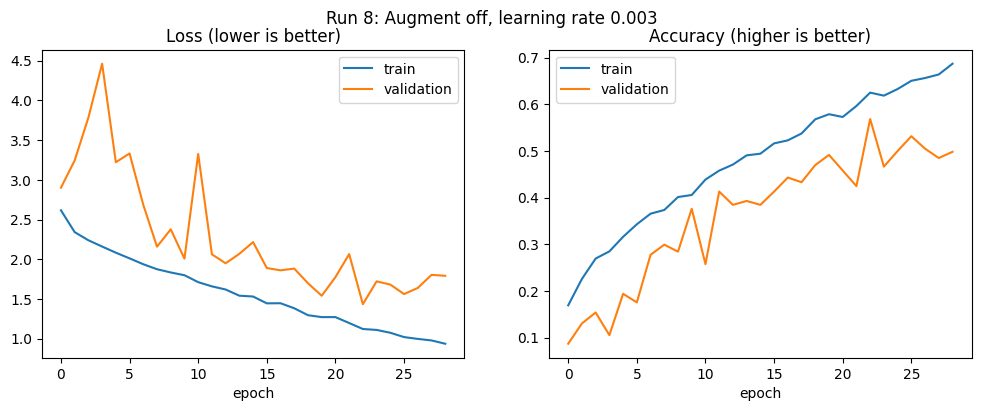

Run 8 | val_acc = 0.5686 | train_acc = 0.6252 | gap = 0.0566 | 0.5 min


In [ ]:
# Experiment 3: build on whatever worked best so far
cfg = dict(baseline_cfg)
cfg["augment"] = False               # keep what helped
cfg["learning_rate"] = 0.003        # CHANGE: the new thing you are testing

model = run_experiment(cfg, notes="Augment off, learning rate 0.003")

Epoch 1/30
53/53 - 19s - 351ms/step - accuracy: 0.1758 - loss: 2.5972 - val_accuracy: 0.1254 - val_loss: 2.8970
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2336 - loss: 2.3071 - val_accuracy: 0.2007 - val_loss: 3.0007
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2639 - loss: 2.2302 - val_accuracy: 0.1421 - val_loss: 3.5890
Epoch 4/30
53/53 - 0s - 9ms/step - accuracy: 0.2893 - loss: 2.1518 - val_accuracy: 0.0936 - val_loss: 3.7071
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2908 - loss: 2.1236 - val_accuracy: 0.1706 - val_loss: 2.9758
Epoch 6/30
53/53 - 1s - 9ms/step - accuracy: 0.3250 - loss: 2.0463 - val_accuracy: 0.1839 - val_loss: 3.3511
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3462 - loss: 1.9792 - val_accuracy: 0.2492 - val_loss: 2.8989
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.3624 - loss: 1.9346 - val_accuracy: 0.2559 - val_loss: 2.3297
Epoch 9/30
53/53 - 1s - 24ms/step - accuracy: 0.3775 - loss: 1.8746 - val_accuracy: 0.2726 - val_loss: 2.4120
Epoch 10/3

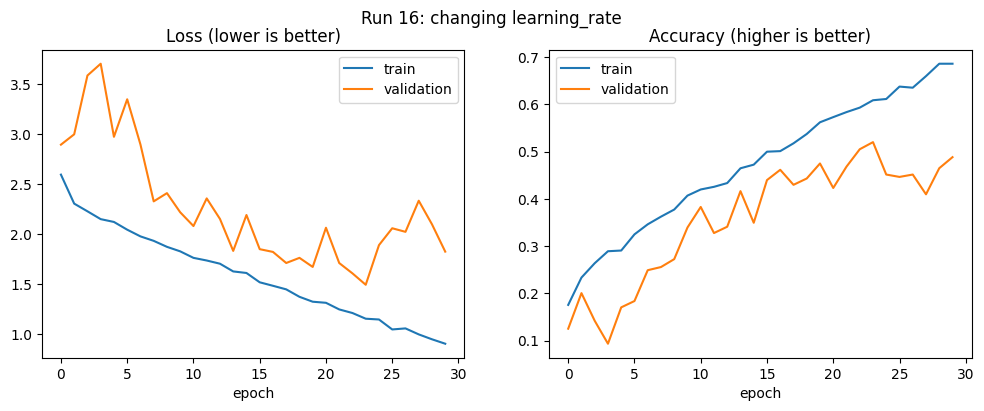

Run 16 | val_acc = 0.5201 | train_acc = 0.6087 | gap = 0.0886 | 0.6 min


In [ ]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003                  # CHANGE

model = run_experiment(cfg, notes="changing learning_rate")

Epoch 1/30
53/53 - 18s - 341ms/step - accuracy: 0.1828 - loss: 2.5488 - val_accuracy: 0.1371 - val_loss: 2.8698
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2309 - loss: 2.3108 - val_accuracy: 0.1104 - val_loss: 3.4584
Epoch 3/30
53/53 - 1s - 9ms/step - accuracy: 0.2743 - loss: 2.2088 - val_accuracy: 0.1154 - val_loss: 3.8390
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3020 - loss: 2.1167 - val_accuracy: 0.1237 - val_loss: 4.2426
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3046 - loss: 2.0845 - val_accuracy: 0.1856 - val_loss: 2.7446
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3497 - loss: 1.9877 - val_accuracy: 0.1873 - val_loss: 3.3606
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3589 - loss: 1.9396 - val_accuracy: 0.3060 - val_loss: 2.1564
Epoch 8/30
53/53 - 1s - 9ms/step - accuracy: 0.3925 - loss: 1.8544 - val_accuracy: 0.2040 - val_loss: 3.3725
Epoch 9/30
53/53 - 0s - 9ms/step - accuracy: 0.4111 - loss: 1.7880 - val_accuracy: 0.2910 - val_loss: 2.5496
Epoch 10/30

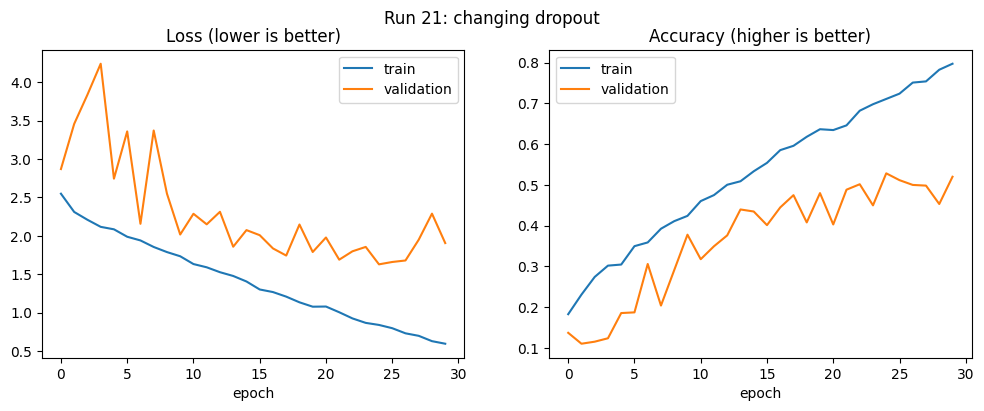

Run 21 | val_acc = 0.5284 | train_acc = 0.7110 | gap = 0.1826 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10                  # CHANGE

model = run_experiment(cfg, notes="changing dropout")

Epoch 1/30
53/53 - 18s - 340ms/step - accuracy: 0.1905 - loss: 2.5238 - val_accuracy: 0.1204 - val_loss: 3.1863 - learning_rate: 0.0030
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2400 - loss: 2.2787 - val_accuracy: 0.1505 - val_loss: 2.9629 - learning_rate: 0.0030
Epoch 3/30
53/53 - 0s - 9ms/step - accuracy: 0.2793 - loss: 2.1832 - val_accuracy: 0.1505 - val_loss: 2.8637 - learning_rate: 0.0030
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2961 - loss: 2.1254 - val_accuracy: 0.1572 - val_loss: 2.9148 - learning_rate: 0.0030
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3158 - loss: 2.0668 - val_accuracy: 0.1773 - val_loss: 2.5635 - learning_rate: 0.0030
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3509 - loss: 1.9767 - val_accuracy: 0.1839 - val_loss: 2.8640 - learning_rate: 0.0030
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3784 - loss: 1.8930 - val_accuracy: 0.2893 - val_loss: 2.3455 - learning_rate: 0.0030
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4067 - loss: 

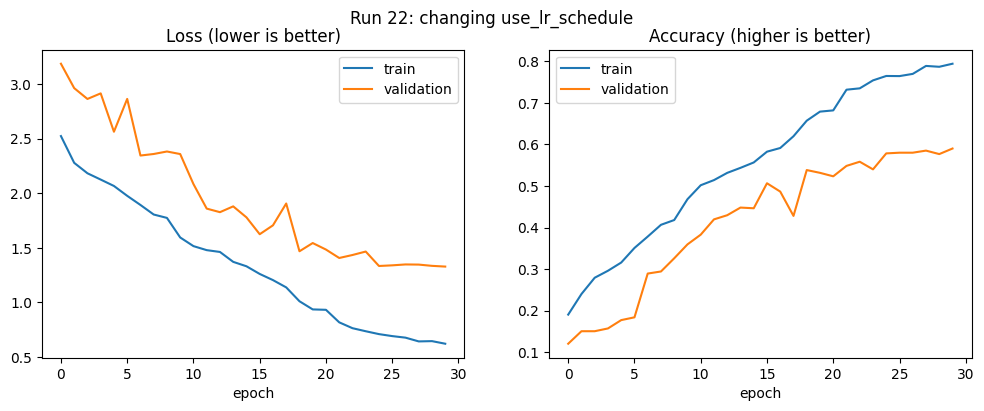

Run 22 | val_acc = 0.5903 | train_acc = 0.7945 | gap = 0.2042 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True                  # CHANGE

model = run_experiment(cfg, notes="changing use_lr_schedule")

Epoch 1/30
53/53 - 20s - 373ms/step - accuracy: 0.1669 - loss: 2.6035 - val_accuracy: 0.0803 - val_loss: 6.3086 - learning_rate: 0.0030
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2250 - loss: 2.3699 - val_accuracy: 0.1472 - val_loss: 2.9504 - learning_rate: 0.0030
Epoch 3/30
53/53 - 1s - 17ms/step - accuracy: 0.2406 - loss: 2.2901 - val_accuracy: 0.1037 - val_loss: 3.3642 - learning_rate: 0.0030
Epoch 4/30
53/53 - 1s - 17ms/step - accuracy: 0.2704 - loss: 2.2032 - val_accuracy: 0.1237 - val_loss: 3.3140 - learning_rate: 0.0030
Epoch 5/30
53/53 - 1s - 20ms/step - accuracy: 0.2976 - loss: 2.1128 - val_accuracy: 0.1622 - val_loss: 2.7726 - learning_rate: 0.0015
Epoch 6/30
53/53 - 1s - 18ms/step - accuracy: 0.3185 - loss: 2.0546 - val_accuracy: 0.1722 - val_loss: 3.2361 - learning_rate: 0.0015
Epoch 7/30
53/53 - 1s - 19ms/step - accuracy: 0.3353 - loss: 2.0036 - val_accuracy: 0.1856 - val_loss: 2.9742 - learning_rate: 0.0015
Epoch 8/30
53/53 - 1s - 18ms/step - accuracy: 0.3704 - loss:

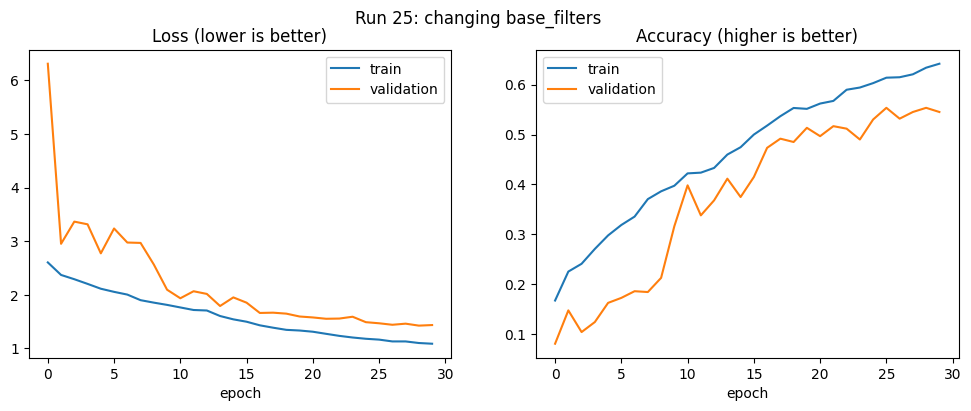

Run 25 | val_acc = 0.5535 | train_acc = 0.6140 | gap = 0.0605 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64                  # CHANGE

model = run_experiment(cfg, notes="changing base_filters")

Epoch 1/30
53/53 - 17s - 317ms/step - accuracy: 0.1896 - loss: 2.5540 - val_accuracy: 0.0886 - val_loss: 6.5746 - learning_rate: 0.0030
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2483 - loss: 2.2833 - val_accuracy: 0.1070 - val_loss: 3.0188 - learning_rate: 0.0030
Epoch 3/30
53/53 - 1s - 17ms/step - accuracy: 0.2828 - loss: 2.2053 - val_accuracy: 0.0870 - val_loss: 3.0987 - learning_rate: 0.0030
Epoch 4/30
53/53 - 1s - 17ms/step - accuracy: 0.2952 - loss: 2.1423 - val_accuracy: 0.1455 - val_loss: 2.8481 - learning_rate: 0.0030
Epoch 5/30
53/53 - 1s - 17ms/step - accuracy: 0.2893 - loss: 2.1177 - val_accuracy: 0.2458 - val_loss: 2.3775 - learning_rate: 0.0030
Epoch 6/30
53/53 - 1s - 17ms/step - accuracy: 0.3206 - loss: 2.0608 - val_accuracy: 0.2659 - val_loss: 2.4741 - learning_rate: 0.0030
Epoch 7/30
53/53 - 1s - 18ms/step - accuracy: 0.3554 - loss: 1.9816 - val_accuracy: 0.3043 - val_loss: 2.2742 - learning_rate: 0.0030
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.3763 - loss:

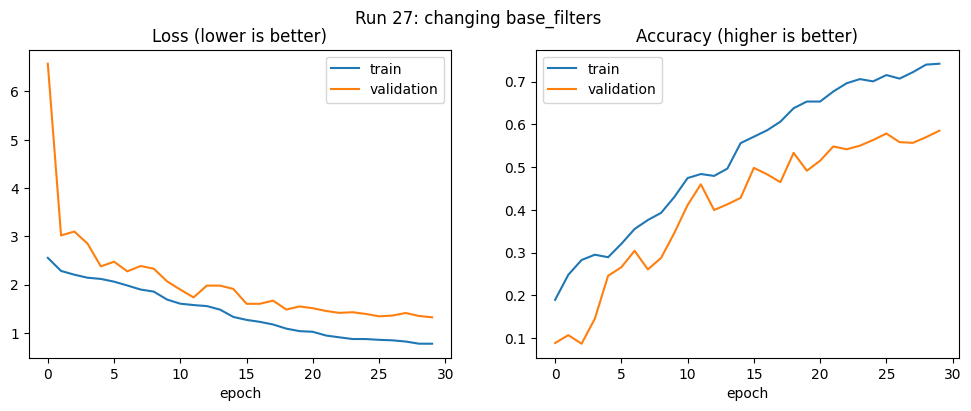

Run 27 | val_acc = 0.5853 | train_acc = 0.7420 | gap = 0.1567 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3                  # CHANGE

model = run_experiment(cfg, notes="changing base_filters")

Epoch 1/30
53/53 - 16s - 308ms/step - accuracy: 0.1914 - loss: 2.5771 - val_accuracy: 0.0936 - val_loss: 4.3290 - learning_rate: 0.0030
Epoch 2/30
53/53 - 1s - 17ms/step - accuracy: 0.2389 - loss: 2.3023 - val_accuracy: 0.1338 - val_loss: 3.0229 - learning_rate: 0.0030
Epoch 3/30
53/53 - 1s - 16ms/step - accuracy: 0.2816 - loss: 2.2187 - val_accuracy: 0.1488 - val_loss: 3.0015 - learning_rate: 0.0030
Epoch 4/30
53/53 - 1s - 16ms/step - accuracy: 0.2858 - loss: 2.1301 - val_accuracy: 0.1221 - val_loss: 3.1407 - learning_rate: 0.0030
Epoch 5/30
53/53 - 1s - 16ms/step - accuracy: 0.3061 - loss: 2.0889 - val_accuracy: 0.1605 - val_loss: 3.0786 - learning_rate: 0.0030
Epoch 6/30
53/53 - 1s - 16ms/step - accuracy: 0.3722 - loss: 1.9361 - val_accuracy: 0.2107 - val_loss: 3.0852 - learning_rate: 0.0015
Epoch 7/30
53/53 - 1s - 16ms/step - accuracy: 0.3904 - loss: 1.8525 - val_accuracy: 0.2625 - val_loss: 2.4833 - learning_rate: 0.0015
Epoch 8/30
53/53 - 1s - 16ms/step - accuracy: 0.3943 - loss:

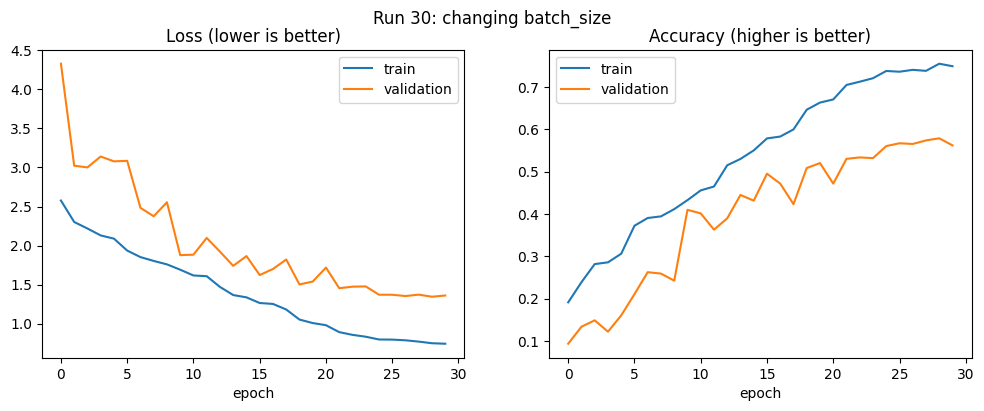

Run 30 | val_acc = 0.5786 | train_acc = 0.7546 | gap = 0.1760 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64                # CHANGE

model = run_experiment(cfg, notes="changing batch_size")

Epoch 1/30
53/53 - 17s - 312ms/step - accuracy: 0.1793 - loss: 2.5866 - val_accuracy: 0.1237 - val_loss: 3.0293 - learning_rate: 0.0030
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2285 - loss: 2.3382 - val_accuracy: 0.1054 - val_loss: 3.2309 - learning_rate: 0.0030
Epoch 3/30
53/53 - 1s - 17ms/step - accuracy: 0.2595 - loss: 2.2464 - val_accuracy: 0.1221 - val_loss: 3.3226 - learning_rate: 0.0030
Epoch 4/30
53/53 - 1s - 17ms/step - accuracy: 0.2899 - loss: 2.1166 - val_accuracy: 0.0886 - val_loss: 3.5301 - learning_rate: 0.0015
Epoch 5/30
53/53 - 1s - 17ms/step - accuracy: 0.3147 - loss: 2.0577 - val_accuracy: 0.1154 - val_loss: 3.3310 - learning_rate: 0.0015
Epoch 6/30
53/53 - 1s - 17ms/step - accuracy: 0.3565 - loss: 1.9424 - val_accuracy: 0.1288 - val_loss: 3.4452 - learning_rate: 7.5000e-04
Epoch 7/30
53/53 - 1s - 17ms/step - accuracy: 0.3837 - loss: 1.8660 - val_accuracy: 0.1605 - val_loss: 2.9779 - learning_rate: 7.5000e-04
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.4022

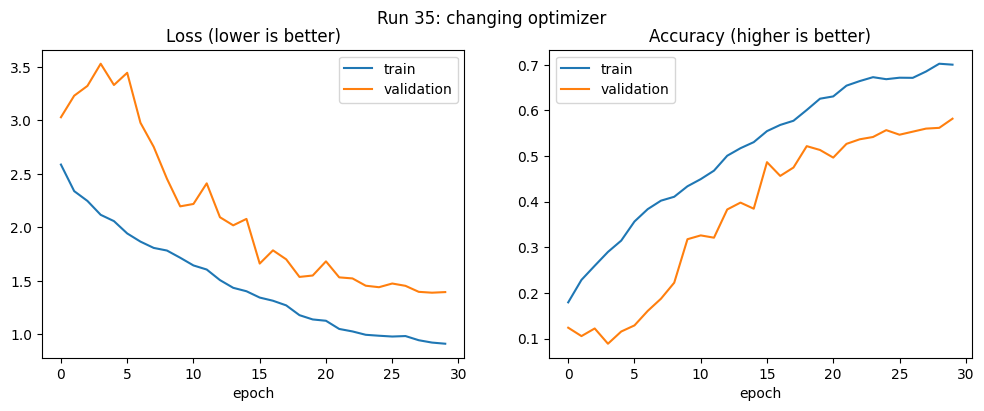

Run 35 | val_acc = 0.5819 | train_acc = 0.7004 | gap = 0.1184 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64
cfg["optimizer"] = "adam"              # CHANGE

model = run_experiment(cfg, notes="changing optimizer")

Epoch 1/35
53/53 - 17s - 313ms/step - accuracy: 0.1849 - loss: 2.5662 - val_accuracy: 0.1020 - val_loss: 4.2928 - learning_rate: 0.0030
Epoch 2/35
53/53 - 1s - 18ms/step - accuracy: 0.2318 - loss: 2.3307 - val_accuracy: 0.1572 - val_loss: 2.9967 - learning_rate: 0.0030
Epoch 3/35
53/53 - 1s - 17ms/step - accuracy: 0.2577 - loss: 2.2611 - val_accuracy: 0.1137 - val_loss: 3.6427 - learning_rate: 0.0030
Epoch 4/35
53/53 - 1s - 17ms/step - accuracy: 0.2757 - loss: 2.1875 - val_accuracy: 0.0970 - val_loss: 3.6648 - learning_rate: 0.0030
Epoch 5/35
53/53 - 1s - 17ms/step - accuracy: 0.3096 - loss: 2.0833 - val_accuracy: 0.1304 - val_loss: 3.0338 - learning_rate: 0.0015
Epoch 6/35
53/53 - 1s - 17ms/step - accuracy: 0.3324 - loss: 2.0080 - val_accuracy: 0.1120 - val_loss: 3.7701 - learning_rate: 0.0015
Epoch 7/35
53/53 - 1s - 17ms/step - accuracy: 0.3733 - loss: 1.9058 - val_accuracy: 0.1739 - val_loss: 2.9717 - learning_rate: 7.5000e-04
Epoch 8/35
53/53 - 1s - 17ms/step - accuracy: 0.3949 - l

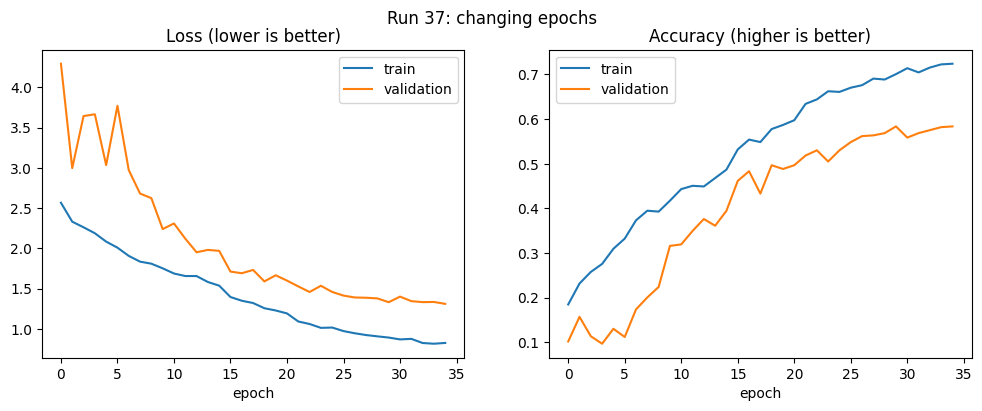

Run 37 | val_acc = 0.5836 | train_acc = 0.7007 | gap = 0.1171 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64
cfg["optimizer"] = "adam"
cfg["epochs"] = 35              # CHANGE

model = run_experiment(cfg, notes="changing epochs")

Epoch 1/35
53/53 - 17s - 312ms/step - accuracy: 0.1690 - loss: 2.5977 - val_accuracy: 0.0920 - val_loss: 3.7218 - learning_rate: 0.0030
Epoch 2/35
53/53 - 1s - 18ms/step - accuracy: 0.2271 - loss: 2.3469 - val_accuracy: 0.1756 - val_loss: 2.7621 - learning_rate: 0.0030
Epoch 3/35
53/53 - 1s - 17ms/step - accuracy: 0.2583 - loss: 2.2732 - val_accuracy: 0.1438 - val_loss: 3.3224 - learning_rate: 0.0030
Epoch 4/35
53/53 - 1s - 17ms/step - accuracy: 0.2630 - loss: 2.1972 - val_accuracy: 0.1104 - val_loss: 3.2063 - learning_rate: 0.0030
Epoch 5/35
53/53 - 1s - 17ms/step - accuracy: 0.3008 - loss: 2.0963 - val_accuracy: 0.1538 - val_loss: 3.0281 - learning_rate: 0.0015
Epoch 6/35
53/53 - 1s - 24ms/step - accuracy: 0.3238 - loss: 2.0319 - val_accuracy: 0.1321 - val_loss: 3.8482 - learning_rate: 0.0015
Epoch 7/35
53/53 - 1s - 17ms/step - accuracy: 0.3586 - loss: 1.9333 - val_accuracy: 0.1622 - val_loss: 3.0275 - learning_rate: 7.5000e-04
Epoch 8/35
53/53 - 1s - 18ms/step - accuracy: 0.3707 - l

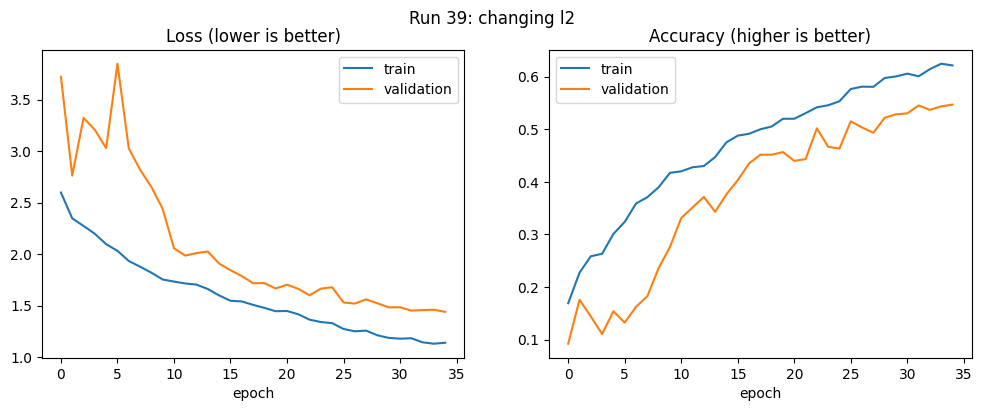

Run 39 | val_acc = 0.5468 | train_acc = 0.6214 | gap = 0.0745 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64
cfg["optimizer"] = "adam"
cfg["epochs"] = 35
cfg["l2"] = 0.0              # CHANGE

model = run_experiment(cfg, notes="changing l2")

Epoch 1/35
53/53 - 17s - 314ms/step - accuracy: 0.1663 - loss: 2.6060 - val_accuracy: 0.1254 - val_loss: 3.0054 - learning_rate: 0.0030
Epoch 2/35
53/53 - 8s - 145ms/step - accuracy: 0.2283 - loss: 2.3334 - val_accuracy: 0.1137 - val_loss: 2.9149 - learning_rate: 0.0030
Epoch 3/35
53/53 - 1s - 17ms/step - accuracy: 0.2619 - loss: 2.2499 - val_accuracy: 0.1271 - val_loss: 2.9896 - learning_rate: 0.0030
Epoch 4/35
53/53 - 1s - 17ms/step - accuracy: 0.2760 - loss: 2.1699 - val_accuracy: 0.1154 - val_loss: 3.6265 - learning_rate: 0.0030
Epoch 5/35
53/53 - 1s - 17ms/step - accuracy: 0.3200 - loss: 2.0561 - val_accuracy: 0.0970 - val_loss: 3.2086 - learning_rate: 0.0015
Epoch 6/35
53/53 - 1s - 17ms/step - accuracy: 0.3418 - loss: 1.9880 - val_accuracy: 0.1455 - val_loss: 3.2051 - learning_rate: 0.0015
Epoch 7/35
53/53 - 1s - 17ms/step - accuracy: 0.3784 - loss: 1.9010 - val_accuracy: 0.2040 - val_loss: 2.6057 - learning_rate: 7.5000e-04
Epoch 8/35
53/53 - 1s - 17ms/step - accuracy: 0.3875 - 

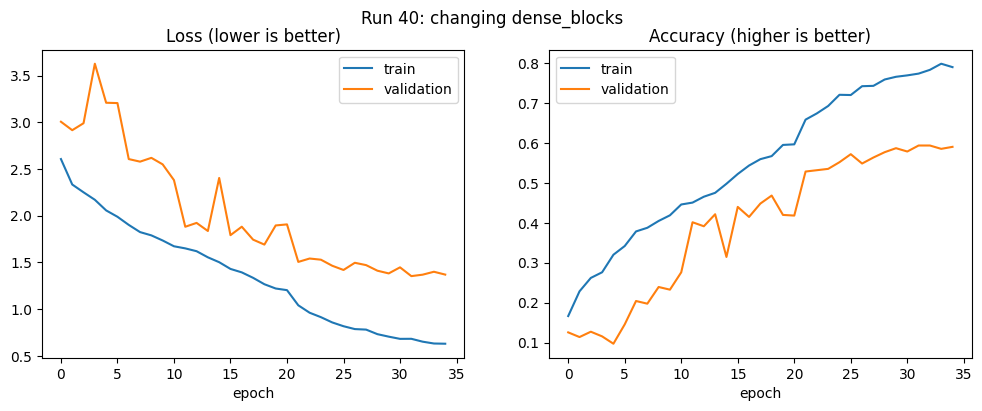

Run 40 | val_acc = 0.5936 | train_acc = 0.7738 | gap = 0.1802 | 0.9 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64
cfg["optimizer"] = "adam"
cfg["epochs"] = 35
cfg["l2"] = 0.0
cfg["dense_blocks"] = 128            # CHANGE

model = run_experiment(cfg, notes="changing dense_blocks")

Epoch 1/35
53/53 - 17s - 314ms/step - accuracy: 0.1710 - loss: 2.6020 - val_accuracy: 0.1706 - val_loss: 3.0851 - learning_rate: 0.0030
Epoch 2/35
53/53 - 1s - 18ms/step - accuracy: 0.2173 - loss: 2.3452 - val_accuracy: 0.1472 - val_loss: 2.8016 - learning_rate: 0.0030
Epoch 3/35
53/53 - 1s - 17ms/step - accuracy: 0.2563 - loss: 2.2760 - val_accuracy: 0.1304 - val_loss: 3.0877 - learning_rate: 0.0030
Epoch 4/35
53/53 - 1s - 17ms/step - accuracy: 0.2802 - loss: 2.1961 - val_accuracy: 0.1589 - val_loss: 3.1477 - learning_rate: 0.0030
Epoch 5/35
53/53 - 1s - 17ms/step - accuracy: 0.3067 - loss: 2.0994 - val_accuracy: 0.1656 - val_loss: 2.8294 - learning_rate: 0.0015
Epoch 6/35
53/53 - 1s - 17ms/step - accuracy: 0.3235 - loss: 2.0595 - val_accuracy: 0.1538 - val_loss: 3.0179 - learning_rate: 0.0015
Epoch 7/35
53/53 - 1s - 17ms/step - accuracy: 0.3353 - loss: 1.9744 - val_accuracy: 0.1572 - val_loss: 2.9183 - learning_rate: 7.5000e-04
Epoch 8/35
53/53 - 1s - 17ms/step - accuracy: 0.3518 - l

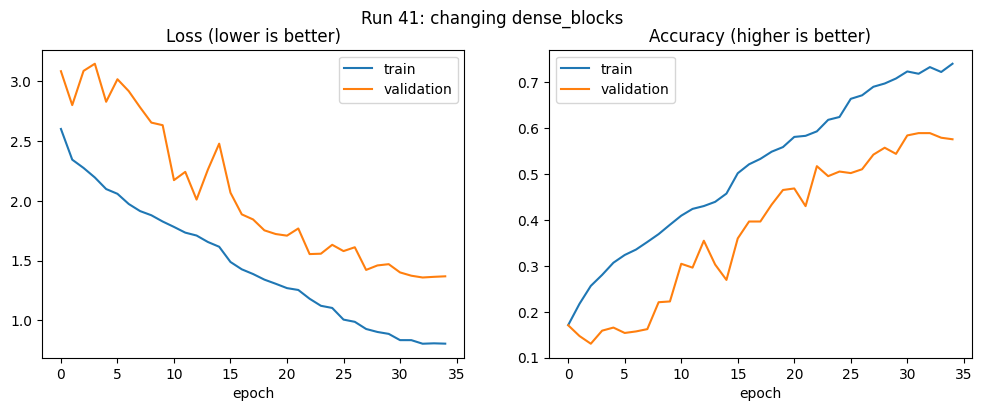

Run 41 | val_acc = 0.5886 | train_acc = 0.7178 | gap = 0.1292 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["dropout"] = 0.10
cfg["use_lr_schedule"] = True
cfg["base_filters"] = 64
cfg["num_blocks"] = 3
cfg["batch_size"] = 64
cfg["optimizer"] = "adam"
cfg["epochs"] = 35
cfg["l2"] = 0.0
cfg["dense_blocks"] = 128
cfg["patience"] = 8            # CHANGE

model = run_experiment(cfg, notes="changing patience")

## Step 6: Your results table

This is your lab notebook. Look for patterns: which settings help, which hurt, which hardly matter. Copy the most interesting rows into the table in your README or report, and write one sentence about what you learned from each.

,run,notes,learning_rate,batch_size,optimizer,dropout,l2,base_filters,num_blocks,dense_units,augment,use_lr_schedule,train_acc,val_acc,gap,best_epoch,minutes
0,40,changing dense_blocks,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7738,0.5936,0.1802,32,0.9
1,22,changing use_lr_schedule,0.0030,64,adam,0.10,0.0,32,3,256,False,True,0.7945,0.5903,0.2042,30,0.6
2,41,changing dense_blocks,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7178,0.5886,0.1292,32,0.8
3,27,changing base_filters,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7420,0.5853,0.1567,30,0.7
4,37,changing epochs,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7007,0.5836,0.1171,30,0.8
5,3,Turned on data augmentation,0.0010,64,adam,0.25,0.0,32,3,256,False,False,0.7452,0.5836,0.1616,30,0.6
6,35,changing optimizer,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7004,0.5819,0.1184,30,0.7
7,2,Turned on data augmentation,0.0010,64,adam,0.25,0.0,32,3,256,True,False,0.6019,0.5803,0.0216,29,0.6
8,30,changing batch_size,0.0030,64,adam,0.10,0.0,64,3,256,False,True,0.7546,0.5786,0.1760,29,0.7
9,1,"Baseline, nothing tuned",0.0010,64,adam,0.25,0.0,32,3,256,False,False,0.7399,0.5702,0.1697,29,0.8


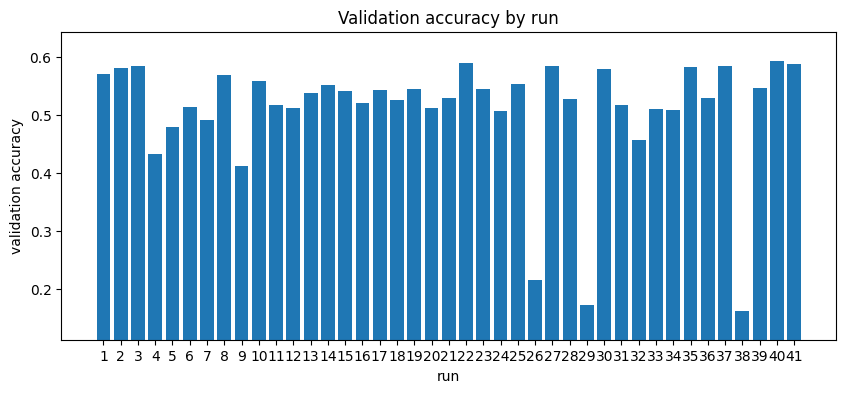

In [ ]:
log_df = pd.DataFrame(experiment_log)
shown = [c for c in ["run", "notes", "learning_rate", "batch_size", "optimizer", "dropout", "l2",
                     "base_filters", "num_blocks", "dense_units", "augment", "use_lr_schedule",
                     "train_acc", "val_acc", "gap", "best_epoch", "minutes"] if c in log_df.columns]
display(log_df[shown].sort_values("val_acc", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 4))
plt.bar(log_df["run"].astype(str), log_df["val_acc"])
plt.xlabel("run"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy by run")
plt.ylim(max(0, log_df["val_acc"].min() - 0.05), min(1, log_df["val_acc"].max() + 0.05))
plt.show()

In [ ]:
# Optional: download your log (and keep it safe, Colab deletes files when the session ends)
from google.colab import files
files.download("experiment_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7: The final exam (run this ONCE)

When you are finished tuning, evaluate your best saved model on the test set. This tells you how well it will work on brand new images.

If you now go back and tune further because of this number, it stops being a fair test. So do this only when you are done.

In [ ]:
best_model = keras.models.load_model(BEST_MODEL_FILE)
test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best validation accuracy during tuning: {best_val_so_far:.4f}")
print(f"FINAL TEST ACCURACY:                    {test_acc:.4f}")

# Which classes does the model handle best and worst?
preds = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
per_class = pd.Series({CLASS_NAMES[c]: float(np.mean(preds[y_test == c] == c)) for c in range(NUM_CLASSES)}).sort_values()
print("\nHardest classes:\n", per_class.head(5).round(2).to_string())
print("\nEasiest classes:\n", per_class.tail(5).round(2).to_string())

Best validation accuracy during tuning: 0.5936
FINAL TEST ACCURACY:                    0.5813

Hardest classes:
 bowl            0.29
snail           0.30
lizard          0.39
sweet_pepper    0.42
clock           0.42

Easiest classes:
 apple         0.76
keyboard      0.77
orange        0.78
forest        0.80
skyscraper    0.84


## Reflection questions

Write short answers in a text cell or in your report:

1. Which single change gave the biggest improvement? Why do you think it helped?
2. Did any change make results worse? What does that teach you?
3. Look at the `gap` column. When was your model overfitting the most?
4. How different were your validation and test accuracy? What would a very large difference mean?
5. If you had two more hours, what would you try next?